In [1]:
# import all the libraries required for this chapter
# Machine Learning Libraries: scikit-learn, keras and tensorflow

# setting seed for model reproducibility
!pip install scikeras
seed_value = 42
import os
os.environ['PYTHONHASHSEED'] = str(seed_value)
import random
random.seed(seed_value)
import numpy as np
np.random.seed(seed_value)
import tensorflow as tf
tf.random.set_seed(seed_value)
import pandas as pd

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.svm import SVR, SVC
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import normalize, Normalizer, StandardScaler, OneHotEncoder, LabelEncoder
from sklearn import metrics
from sklearn.compose import ColumnTransformer
import sklearn.cluster as cluster
import lightgbm as lgb
import xgboost as xgb

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, load_model
from scikeras.wrappers import KerasRegressor, KerasClassifier
from tensorflow.keras.utils import to_categorical as np_utils

# plotting libraries
import matplotlib as mpl
import matplotlib.style
import seaborn as sns  # visualization
import matplotlib.pyplot as plt
# formatting for decimal places
pd.set_option("display.float_format", "{:.2f}".format)
plt.style.use("seaborn-v0_8-white")
sns.set_style("white")
import warnings
warnings.filterwarnings('ignore')

## --------   For Google CoLab Only   --------
## Run this cell to download the dataset automatically. Skip if you already have 'Merged_Data.csv'.

In [2]:
!pip install gdown --quiet
import gdown


url = ' https://drive.google.com/uc?id=1189ESk9vlZuklYHLhIlq_tJ61TSwMryY'
gdown.download(url, 'Merged_Data.csv', quiet=False)

data = pd.read_csv('Merged_Data.csv')
data.info()

Downloading...
From:  https://drive.google.com/uc?id=1189ESk9vlZuklYHLhIlq_tJ61TSwMryY
To: /content/Merged_Data.csv
100%|██████████| 611k/611k [00:00<00:00, 8.98MB/s]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5127 entries, 0 to 5126
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   WELL NAME             5127 non-null   object 
 1   DEPTH (M)             5127 non-null   float64
 2   BVW (V/V)             4891 non-null   float64
 3   CARB_FLAG (UNITLESS)  4980 non-null   float64
 4   COAL_FLAG (UNITLESS)  5127 non-null   float64
 5   KLOGH (MD)            4891 non-null   float64
 6   PHIF (V/V)            4891 non-null   float64
 7   RHOFL (G/CM3)         5127 non-null   float64
 8   RHOMA (G/CM3)         4891 non-null   float64
 9   RW (OHMM)             4891 non-null   float64
 10  SAND_FLAG (UNITLESS)  4891 non-null   float64
 11  SW (V/V)              4891 non-null   float64
 12  TEMP (DEGC)           4891 non-null   float64
 13  VSH (V/V)             4891 non-null   float64
 14  LITHOTYPE             5127 non-null   object 
dtypes: float64(13), objec

## Run this cell if you already have 'Merged_Data.csv'.

In [3]:
# import the .csv file as a dataframe - Raw Data File
data = pd.read_csv('./data/Merged_Data.csv')
data.info()

FileNotFoundError: [Errno 2] No such file or directory: './data/Merged_Data.csv'

## Continue...

In [4]:
# Basic Exploratory Data Analysis and Data Cleaning
print(data.head(10))
print('Shape of Dataset (rows,columns):', data.shape)

   WELL NAME  DEPTH (M)  BVW (V/V)  CARB_FLAG (UNITLESS)  \
0  15/9-19 A    3666.59       0.11                  0.00   
1  15/9-19 A    3666.74       0.11                  0.00   
2  15/9-19 A    3666.90       0.11                  0.00   
3  15/9-19 A    3667.05       0.11                  0.00   
4  15/9-19 A    3667.20       0.12                  0.00   
5  15/9-19 A    3667.35       0.11                  0.00   
6  15/9-19 A    3667.51       0.12                  0.00   
7  15/9-19 A    3667.66       0.12                  0.00   
8  15/9-19 A    3667.81       0.13                  0.00   
9  15/9-19 A    3667.96       0.13                  0.00   

   COAL_FLAG (UNITLESS)  KLOGH (MD)  PHIF (V/V)  RHOFL (G/CM3)  RHOMA (G/CM3)  \
0                  0.00        0.00        0.20           0.80           2.66   
1                  0.00        0.00        0.22           0.80           2.66   
2                  0.00        0.00        0.24           0.80           2.66   
3              

Until this point there is no data cleaning being performed. The objective of the next few sections is to wrangle the data and prepare it for the machine learning model stage. The current dataset consists of petrophysical properties from two different wells in Volve field. A majority of columns have float datatype except Well Name and Lithotype. In the case of regression problems, only quantitative columns would be considered, whereas in the case of classification, 'Lithotype' would be the response variable.

<Axes: >

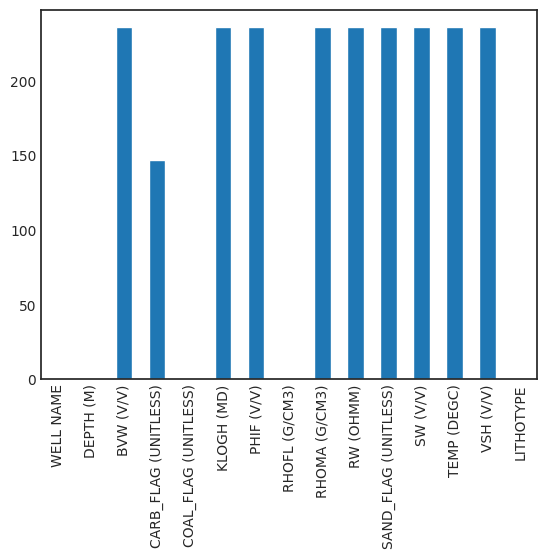

In [5]:
# Find number of empty/NA values in each column
data.isna().sum().plot(kind="bar")

In [6]:
# Descriptive Statistics
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
WELL NAME,5127,2,15/9-19 BT2,3162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEPTH (M),5127.00,NaN,NaN,NaN,3935.10,153.56,3666.59,3814.95,3912.57,4054.53,4249.83
BVW (V/V),4891.00,NaN,NaN,NaN,0.10,0.06,0.00,0.06,0.09,0.12,0.25
CARB_FLAG (UNITLESS),4980.00,NaN,NaN,NaN,0.03,0.18,0.00,0.00,0.00,0.00,1.00
COAL_FLAG (UNITLESS),5127.00,NaN,NaN,NaN,0.01,0.07,0.00,0.00,0.00,0.00,1.00
KLOGH (MD),4891.00,NaN,NaN,NaN,199.85,700.43,0.00,0.00,0.00,23.31,13705.31
PHIF (V/V),4891.00,NaN,NaN,NaN,0.14,0.06,0.00,0.10,0.14,0.20,0.36
RHOFL (G/CM3),5127.00,NaN,NaN,NaN,0.86,0.05,0.80,0.80,0.90,0.90,0.90
RHOMA (G/CM3),4891.00,NaN,NaN,NaN,2.66,0.01,2.63,2.65,2.66,2.66,2.71
RW (OHMM),4891.00,NaN,NaN,NaN,0.02,0.00,0.02,0.02,0.02,0.02,0.02


<Axes: >

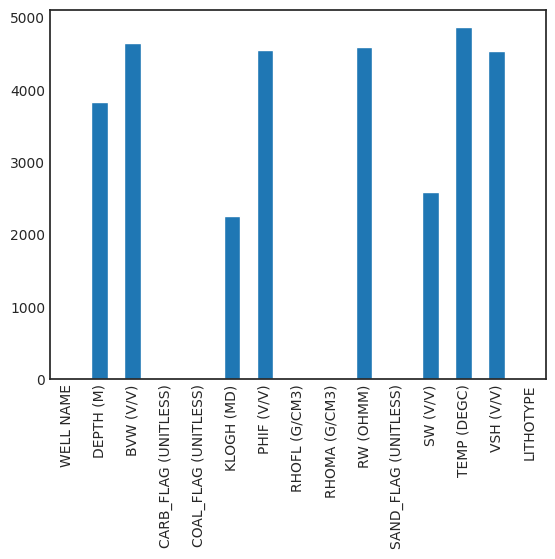

In [7]:
# Number of unique values
data.nunique().plot(kind="bar")

<Axes: >

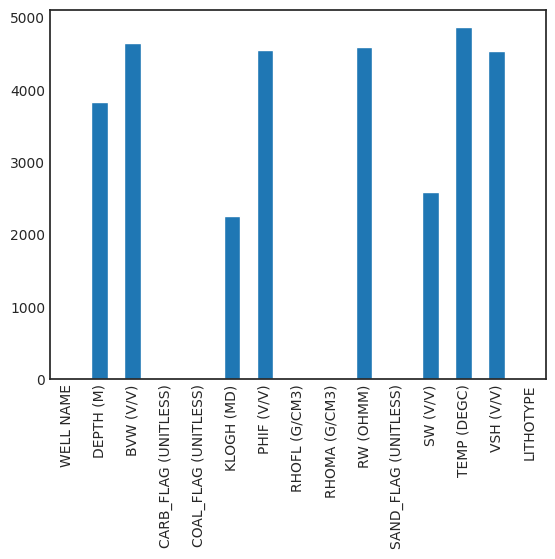

In [8]:
# Number of unique values
data.nunique().plot(kind="bar")

<Axes: >

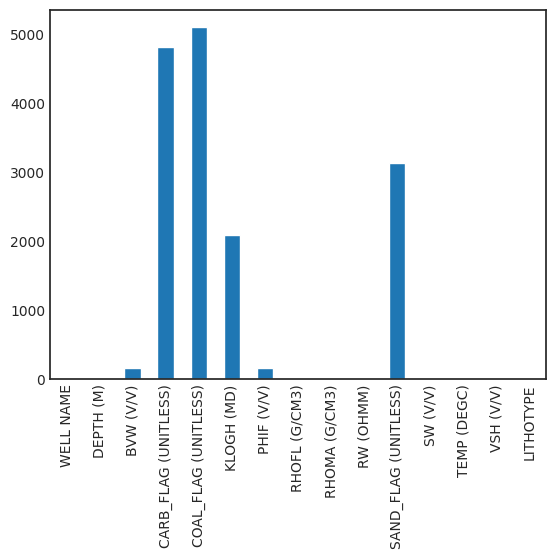

In [9]:
# Data Cleaning - How many columns have Null or value=0
data[data == 0].count(axis=0).plot(kind='bar')

In [10]:
data.dropna(inplace=True)
print('Shape of Dataset (rows,columns):', data.shape)

Shape of Dataset (rows,columns): (4818, 15)


<Axes: xlabel='TEMP (DEGC)', ylabel='Density'>

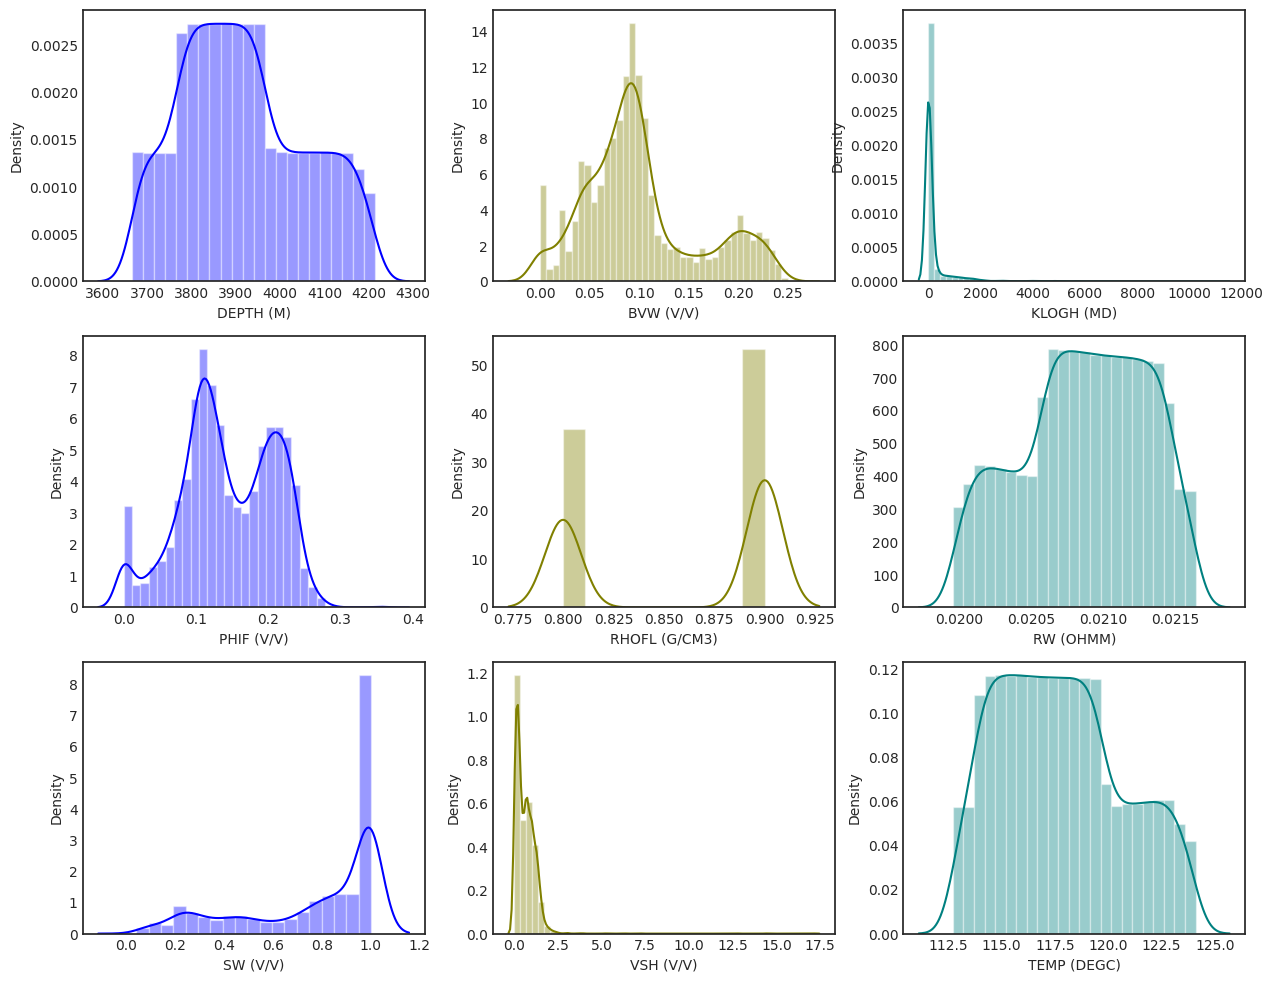

In [11]:
# Histogram - Distributions of continuous variables - only key features are shown here
# sns.set(color_codes=True)
f, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=False)
sns.distplot(data["DEPTH (M)"], color="blue", ax=axes[0, 0])
sns.distplot(data["BVW (V/V)"], color="olive", ax=axes[0, 1])
sns.distplot(data["KLOGH (MD)"], color="teal", ax=axes[0, 2])
sns.distplot(data["PHIF (V/V)"], color="blue", ax=axes[1, 0])
sns.distplot(data["RHOFL (G/CM3)"], color="olive", ax=axes[1, 1])
sns.distplot(data["RW (OHMM)"], color="teal", ax=axes[1, 2])
sns.distplot(data["SW (V/V)"], color="blue", ax=axes[2, 0])
sns.distplot(data["VSH (V/V)"], color="olive", ax=axes[2, 1])
sns.distplot(data["TEMP (DEGC)"], color="teal", ax=axes[2, 2])

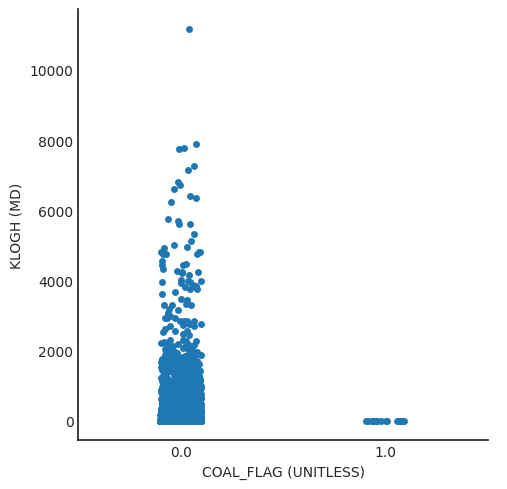

In [12]:
# plotting some categorical variables
sns.catplot(x="COAL_FLAG (UNITLESS)", y="KLOGH (MD)", data=data)
# sns.catplot(x="SAND_FLAG (UNITLESS)", y="KLOGH (MD)", data=data)
# sns.catplot(x="RHOFL (G/CM3)", y="KLOGH (MD)", data=data)

<Axes: xlabel='SAND_FLAG (UNITLESS)'>

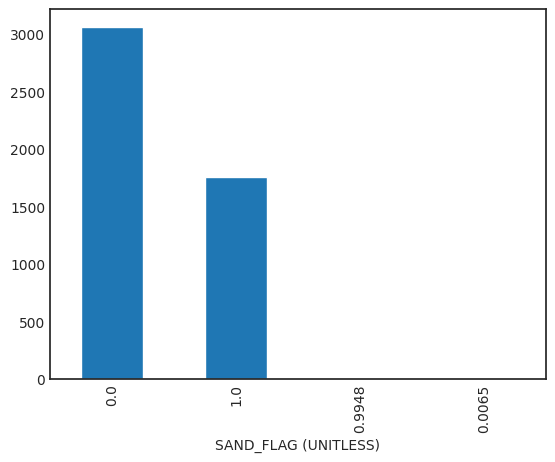

In [13]:
# data['CARB_FLAG (UNITLESS)'].value_counts().plot(kind='bar')
# data['COAL_FLAG (UNITLESS)'].value_counts().plot(kind='bar')
data['SAND_FLAG (UNITLESS)'].value_counts().plot(kind='bar')

<Axes: ylabel='TEMP (DEGC)'>

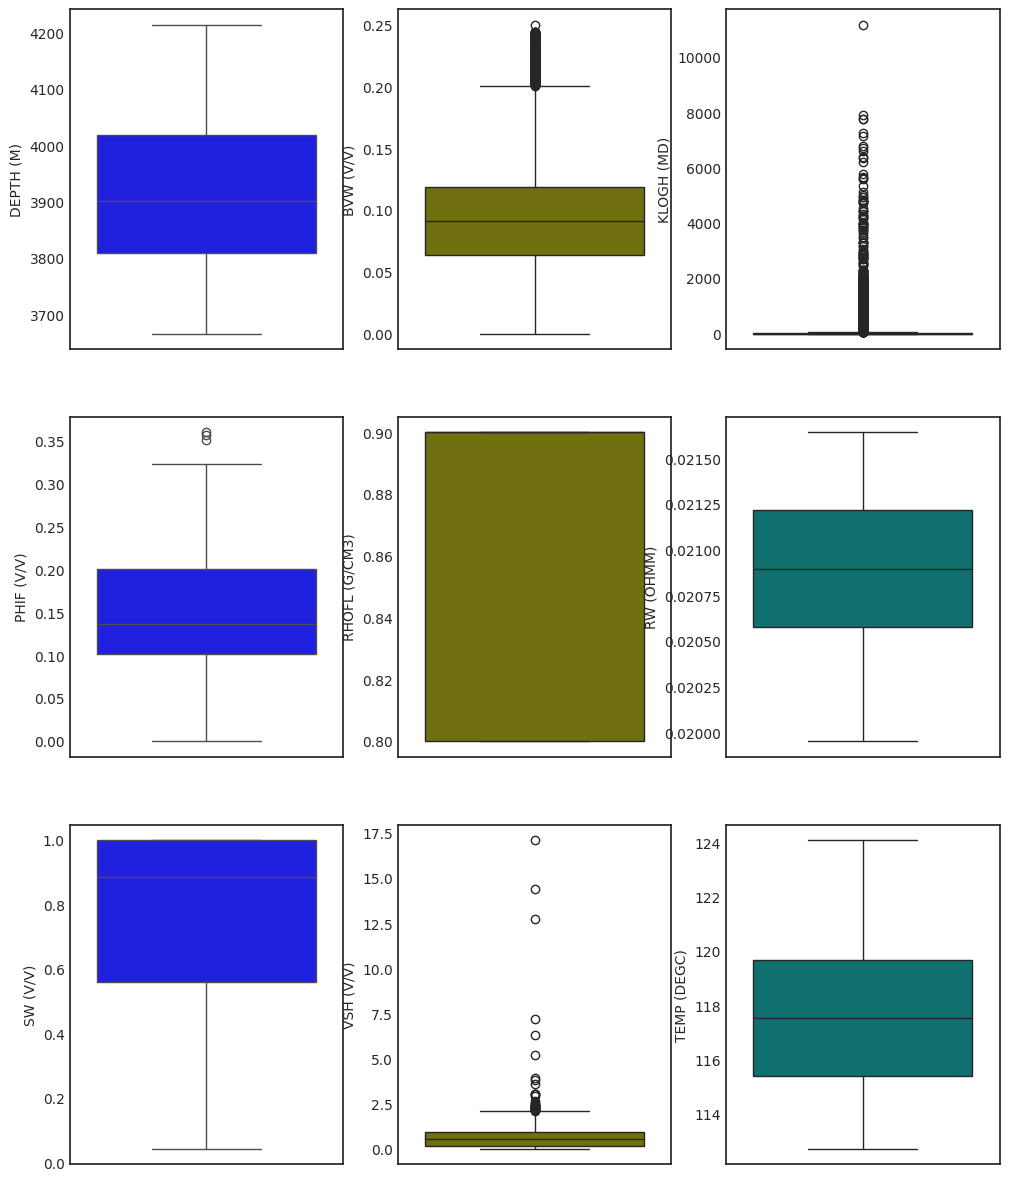

In [14]:
# Box Plots - Useful Tool to detect outliers
f, axes = plt.subplots(3, 3, figsize=(12, 15), sharex=False)
sns.boxplot(data["DEPTH (M)"], color="blue", ax=axes[0, 0])
sns.boxplot(data["BVW (V/V)"], color="olive", ax=axes[0, 1])
sns.boxplot(data["KLOGH (MD)"], color="teal", ax=axes[0, 2])
sns.boxplot(data["PHIF (V/V)"], color="blue", ax=axes[1, 0])
sns.boxplot(data["RHOFL (G/CM3)"], color="olive", ax=axes[1, 1])
sns.boxplot(data["RW (OHMM)"], color="teal", ax=axes[1, 2])
sns.boxplot(data["SW (V/V)"], color="blue", ax=axes[2, 0])
sns.boxplot(data["VSH (V/V)"], color="olive", ax=axes[2, 1])
sns.boxplot(data["TEMP (DEGC)"], color="teal", ax=axes[2, 2])

(13.5, -0.5)

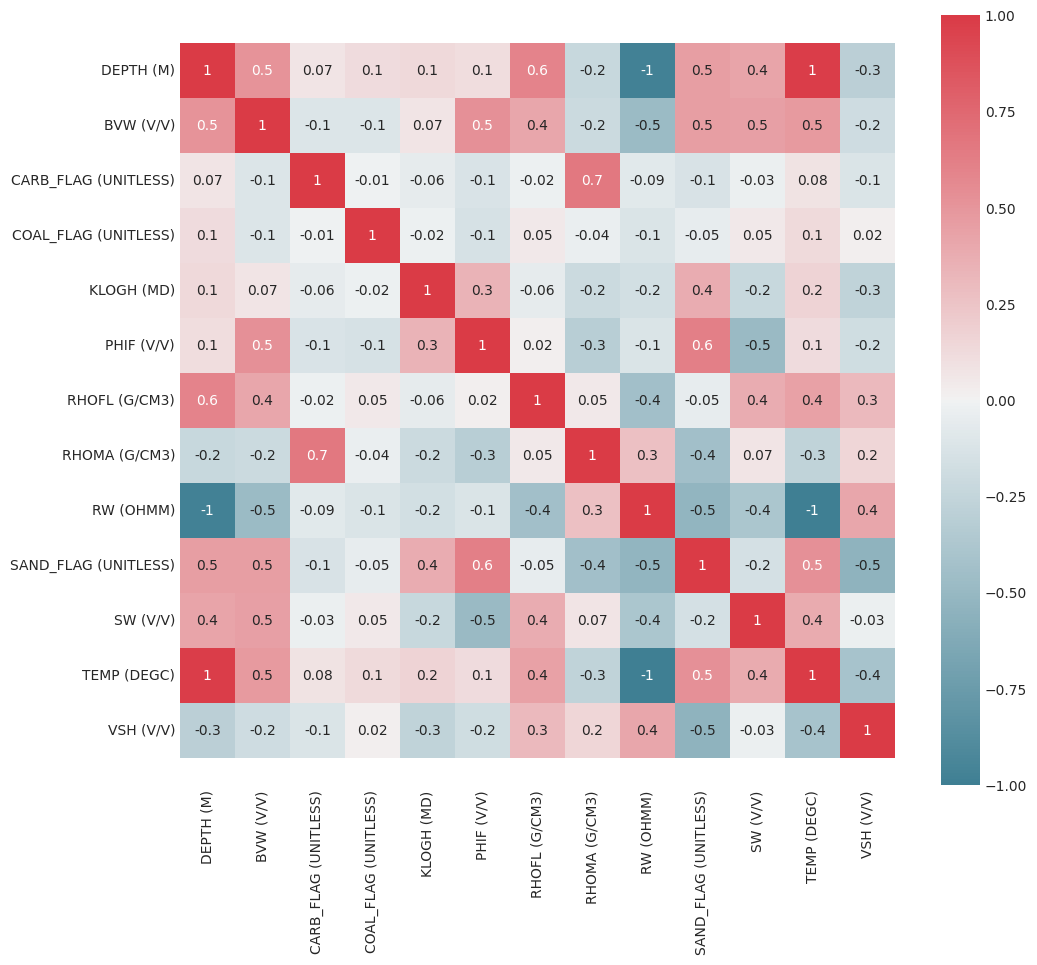

In [15]:
# heatmap to visualize any collinearlity between variables
plt.figure(figsize=(12, 10))
# Colormap definition
cmap = sns.diverging_palette(220, 10, as_cmap=True)
numeric_data = data.iloc[:, 1:-1]
sns.heatmap(numeric_data.corr(), annot=True, fmt='.1g', vmin=-
            1, vmax=1, center=0, cmap=cmap, square=True)
# matplotlib issue with truncation of top and bottom row
b, t = plt.ylim()
b += 0.5  # Add 0.5 to the bottom
t -= 0.5  # Subtract 0.5 from the top
plt.ylim(b, t)  # update the ylim(bottom, top) values

(array([-0.05,  0.  ,  0.05,  0.1 ,  0.15,  0.2 ,  0.25,  0.3 ,  0.35,
         0.4 ]),
 [Text(-0.05, 0, '−0.05'),
  Text(0.0, 0, '0.00'),
  Text(0.05, 0, '0.05'),
  Text(0.10000000000000002, 0, '0.10'),
  Text(0.15000000000000002, 0, '0.15'),
  Text(0.2, 0, '0.20'),
  Text(0.25000000000000006, 0, '0.25'),
  Text(0.30000000000000004, 0, '0.30'),
  Text(0.35000000000000003, 0, '0.35'),
  Text(0.4, 0, '0.40')])

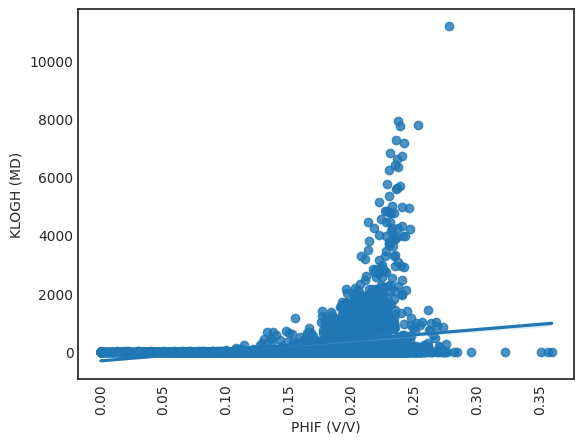

In [16]:
# An example of plot to check collinearity between certain variables
# looking into the correlation between Spacing and NN Spacing - All Zone/Same Zone
sns.regplot(x='PHIF (V/V)', y='KLOGH (MD)', data=data)
plt.xticks(rotation=90)

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4818 entries, 0 to 4890
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   WELL NAME             4818 non-null   object 
 1   DEPTH (M)             4818 non-null   float64
 2   BVW (V/V)             4818 non-null   float64
 3   CARB_FLAG (UNITLESS)  4818 non-null   float64
 4   COAL_FLAG (UNITLESS)  4818 non-null   float64
 5   KLOGH (MD)            4818 non-null   float64
 6   PHIF (V/V)            4818 non-null   float64
 7   RHOFL (G/CM3)         4818 non-null   float64
 8   RHOMA (G/CM3)         4818 non-null   float64
 9   RW (OHMM)             4818 non-null   float64
 10  SAND_FLAG (UNITLESS)  4818 non-null   float64
 11  SW (V/V)              4818 non-null   float64
 12  TEMP (DEGC)           4818 non-null   float64
 13  VSH (V/V)             4818 non-null   float64
 14  LITHOTYPE             4818 non-null   object 
dtypes: float64(13), object(2)


In [18]:
# separate categorical columns
columns_categ = ['WELL NAME', 'LITHOTYPE']
data_cont = data.drop(data[columns_categ], axis=1)  # continous data
# move response variable to end of dataframe
data_cont = data_cont[[col for col in data_cont.columns if col != 'KLOGH (MD)'] + ['KLOGH (MD)']]
data_cont.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4818 entries, 0 to 4890
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   DEPTH (M)             4818 non-null   float64
 1   BVW (V/V)             4818 non-null   float64
 2   CARB_FLAG (UNITLESS)  4818 non-null   float64
 3   COAL_FLAG (UNITLESS)  4818 non-null   float64
 4   PHIF (V/V)            4818 non-null   float64
 5   RHOFL (G/CM3)         4818 non-null   float64
 6   RHOMA (G/CM3)         4818 non-null   float64
 7   RW (OHMM)             4818 non-null   float64
 8   SAND_FLAG (UNITLESS)  4818 non-null   float64
 9   SW (V/V)              4818 non-null   float64
 10  TEMP (DEGC)           4818 non-null   float64
 11  VSH (V/V)             4818 non-null   float64
 12  KLOGH (MD)            4818 non-null   float64
dtypes: float64(13)
memory usage: 527.0 KB


In [19]:
# Splitting the dataset
X = data_cont.iloc[:, :-1]
y = data_cont.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [20]:
print('Shape of Training X:', X_train.shape)
print('Shape of Training y:', y_train.shape)
print('Shape of Test X:', X_test.shape)
print('Shape of Test y:', y_test.shape)

Shape of Training X: (3613, 12)
Shape of Training y: (3613,)
Shape of Test X: (1205, 12)
Shape of Test y: (1205,)


## Regression Algorithms

In [21]:
# defining some functions for regression
# Regression

def reg_metrics(test, pred):
    '''Function returns basic metrics for regression models'''
    print('Mean Absolute Error:', metrics.mean_absolute_error(test, pred))
    print('Mean Squared Error:', metrics.mean_squared_error(test, pred))
    print('Root Mean Squared Error:', np.sqrt(
        metrics.mean_squared_error(test, pred)))
    print('R Squared:', (metrics.r2_score(test, pred)))

def reg_plot(test, pred):
    '''Function returns a regression plot, in the form of a scatter plot'''
    sns.regplot(x=test, y=pred, scatter_kws={
                "color": "black"}, line_kws={"color": "red"})
    plt.xlim(0, max(test))
    plt.ylim(0, max(pred))
    plt.title('Regression Results')
    plt.xlabel('Test Data')
    plt.ylabel('Model Prediction')
    plt.show()

def scatter_plot_comparison(test, pred):
    '''Function returns a comparison between test data and predictions, in the form of line plot'''
    sns.scatterplot(x=test.index, y=test.values, color='red', label='Test data')
    sns.scatterplot(x=test.index, y=pred, color='blue', label='Predicted data')
    plt.title('Prediction')
    plt.xlabel('Observations')
    plt.ylabel('Test and Predicted Values')
    plt.legend()
    plt.show()

def line_plot_comparison(test, pred):
    '''Function returns a comparison between test data and predictions, in the form of line plot'''
    plt.plot(test.values, color='red', label='Test data')
    plt.plot(pred, color='blue', label='Predicted data')
    plt.title('Prediction')
    plt.xlabel('Observations')
    plt.ylabel('Test and Predicted Values')
    plt.legend()
    plt.show()

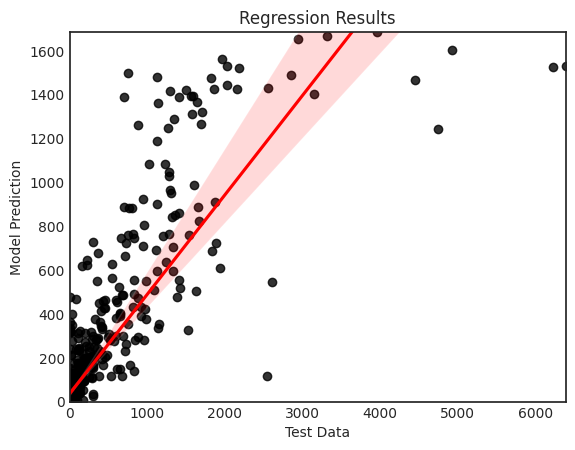

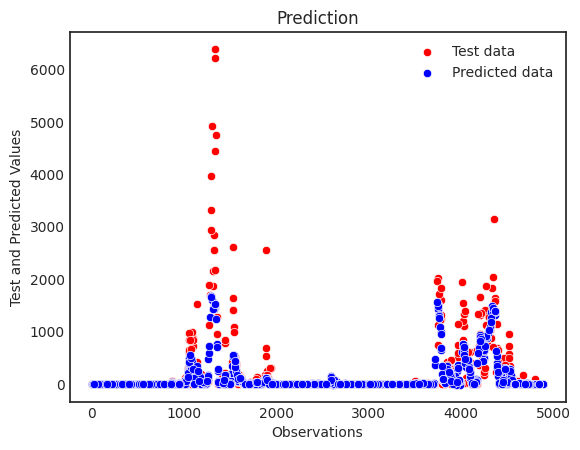

Mean Absolute Error: 82.06388688272045
Mean Squared Error: 112564.25982701963
Root Mean Squared Error: 335.5059758439775
R Squared: 0.6092197399170062


In [22]:
# 2. Support Vector Regression (SVR)
# gaussian kernel selected due to non-linearity in dataset
# Radial basis function - kernel is shown here, other available kernels include 'linear, sigmoid and polynomial'
svr_reg = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=.1)
svr_reg.fit(X_train, y_train)
# Prediction on test data
y_pred_svr = svr_reg.predict(X_test)
# Regression Plot - SVR
reg_plot(y_test, y_pred_svr)
scatter_plot_comparison(y_test, y_pred_svr)
# Metrics for SVR
reg_metrics(y_test, y_pred_svr)

## Classification Algorithms

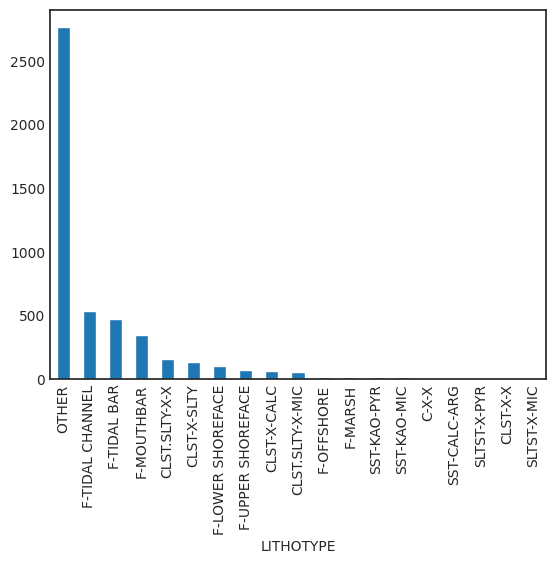

LITHOTYPE
OTHER                2763
F-TIDAL CHANNEL       537
F-TIDAL BAR           476
F-MOUTHBAR            349
CLST.SLTY-X-X         156
CLST-X-SLTY           138
F-LOWER SHOREFACE     105
F-UPPER SHOREFACE      76
CLST-X-CALC            66
CLST.SLTY-X-MIC        59
F-OFFSHORE             20
F-MARSH                20
SST-KAO-PYR            19
SST-KAO-MIC            19
C-X-X                   5
SST-CALC-ARG            4
SLTST-X-PYR             2
CLST-X-X                2
SLTST-X-MIC             2
Name: count, dtype: int64


In [23]:
# The response variable in the classification is 'Lithotype' with all remaining features as input'
data['LITHOTYPE'].value_counts().plot(kind='bar')
plt.show()
count_categ = data['LITHOTYPE'].value_counts()
print(count_categ)

<Axes: xlabel='LITHOTYPE'>

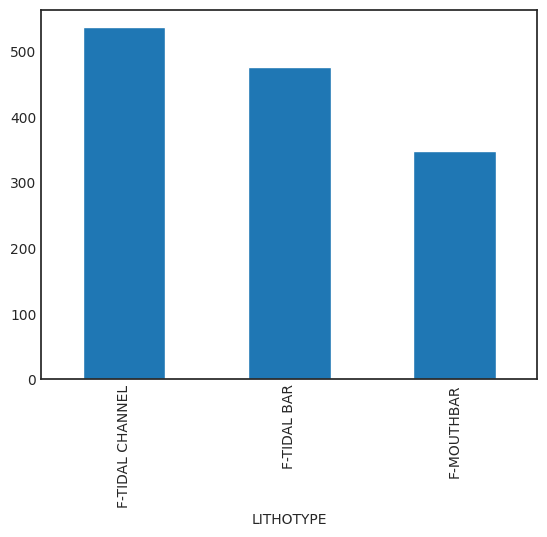

In [24]:
# As observed multiple categories are present, however 'other' won't be considered and
# only the categories with frequency of more than 200 will be included, i.e. 3 categories
data_categ = data[data['LITHOTYPE'].isin(count_categ[count_categ > 200].index)]
data_categ = data_categ[data_categ['LITHOTYPE'] != 'OTHER']
data_categ['LITHOTYPE'].value_counts()
data_categ['LITHOTYPE'].value_counts().plot(kind='bar')

In [25]:
data_categ.drop('WELL NAME', axis=1, inplace=True)
data_categ.info()
data_categ.head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 1362 entries, 1018 to 4658
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   DEPTH (M)             1362 non-null   float64
 1   BVW (V/V)             1362 non-null   float64
 2   CARB_FLAG (UNITLESS)  1362 non-null   float64
 3   COAL_FLAG (UNITLESS)  1362 non-null   float64
 4   KLOGH (MD)            1362 non-null   float64
 5   PHIF (V/V)            1362 non-null   float64
 6   RHOFL (G/CM3)         1362 non-null   float64
 7   RHOMA (G/CM3)         1362 non-null   float64
 8   RW (OHMM)             1362 non-null   float64
 9   SAND_FLAG (UNITLESS)  1362 non-null   float64
 10  SW (V/V)              1362 non-null   float64
 11  TEMP (DEGC)           1362 non-null   float64
 12  VSH (V/V)             1362 non-null   float64
 13  LITHOTYPE             1362 non-null   object 
dtypes: float64(13), object(1)
memory usage: 159.6+ KB


,DEPTH (M),BVW (V/V),CARB_FLAG (UNITLESS),COAL_FLAG (UNITLESS),KLOGH (MD),PHIF (V/V),RHOFL (G/CM3),RHOMA (G/CM3),RW (OHMM),SAND_FLAG (UNITLESS),SW (V/V),TEMP (DEGC),VSH (V/V),LITHOTYPE
1018,3821.73,0.06,0.00,0.00,121.27,0.17,0.80,2.66,0.02,1.00,0.38,116.35,0.14,F-TIDAL BAR
1019,3821.89,0.05,1.00,0.00,0.10,0.12,0.80,2.71,0.02,0.00,0.44,116.35,0.12,F-TIDAL BAR
1020,3822.04,0.05,1.00,0.00,0.10,0.12,0.80,2.71,0.02,0.00,0.39,116.36,0.13,F-TIDAL BAR
1021,3822.19,0.04,1.00,0.00,0.10,0.11,0.80,2.71,0.02,0.00,0.38,116.36,0.11,F-TIDAL BAR
1022,3822.34,0.04,1.00,0.00,0.10,0.10,0.80,2.71,0.02,0.00,0.41,116.36,0.13,F-TIDAL BAR
1023,3822.50,0.04,1.00,0.00,0.10,0.10,0.80,2.71,0.02,0.00,0.44,116.37,0.11,F-TIDAL BAR
1024,3822.65,0.05,1.00,0.00,0.10,0.14,0.80,2.71,0.02,1.00,0.36,116.37,0.13,F-TIDAL BAR
1025,3822.80,0.05,0.00,0.00,43.90,0.14,0.80,2.66,0.02,1.00,0.37,116.37,0.16,F-TIDAL BAR
1026,3822.95,0.05,0.00,0.00,84.11,0.16,0.80,2.66,0.02,1.00,0.32,116.38,0.15,F-TIDAL BAR
1027,3823.11,0.05,0.00,0.00,79.38,0.15,0.80,2.66,0.02,1.00,0.34,116.38,0.14,F-TIDAL BAR


In [26]:
X = data_categ.iloc[:, :-1]
y = data_categ.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [27]:
print('Shape of Training X:', X_train.shape)
print('Shape of Training y:', y_train.shape)
print('Shape of Test X:', X_test.shape)
print('Shape of Test y:', y_test.shape)

Shape of Training X: (1021, 13)
Shape of Training y: (1021,)
Shape of Test X: (341, 13)
Shape of Test y: (341,)


In [28]:
# defining function for classification metrics
def clf_metrics(test, pred):
    '''Function returns basic metrics for classification models'''
    print('Classification Accuracy Score:', accuracy_score(test, pred))
    print('Confusion Matrix: \n', confusion_matrix(test, pred))
    print('Classification Report: \n', classification_report(test, pred))

In [29]:
# 2. SVC
clf_svc = SVC()
clf_svc.fit(X_train, y_train)
# Prediction on test data
y_pred_svc = clf_svc.predict(X_test)
# Accuracy Metrics
clf_metrics(y_test, y_pred_svc)

Classification Accuracy Score: 0.6217008797653959
Confusion Matrix: 
 [[  0  76  11]
 [  0 103  16]
 [  0  26 109]]
Classification Report: 
                  precision    recall  f1-score   support

     F-MOUTHBAR       0.00      0.00      0.00        87
    F-TIDAL BAR       0.50      0.87      0.64       119
F-TIDAL CHANNEL       0.80      0.81      0.80       135

       accuracy                           0.62       341
      macro avg       0.43      0.56      0.48       341
   weighted avg       0.49      0.62      0.54       341



#HyperParameter

Hyper-parameter Optimization
--------------------------------------------

Install Python library Hyperopt using either of the two commands:
- conda install -c conda-forge hyperopt
- pip install hyperopt

### Load required libraries

In [31]:
RAND_SEED = 12345
import numpy as np
np.random.seed(RAND_SEED)
import random
random.seed(RAND_SEED)

import pandas as pd
from hyperopt import fmin, tpe, hp, Trials

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

### Read and prepare data

In [32]:
# import the .csv file as a dataframe - Raw Data File
import gdown


url = ' https://drive.google.com/uc?id=17rovM_1FuqRMGNZ9XTq8cq4NMBWQZ6JB'
InputDataFile = 'Lithotype_Data.csv'
gdown.download(url, InputDataFile, quiet=False)


df = pd.read_csv(InputDataFile)
X = df.iloc[:, :-1]
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
y = df.iloc[:, -1]

TEST_FRAC = 0.25
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_FRAC, random_state=RAND_SEED)

Downloading...
From:  https://drive.google.com/uc?id=17rovM_1FuqRMGNZ9XTq8cq4NMBWQZ6JB
To: /content/Lithotype_Data.csv
100%|██████████| 118k/118k [00:00<00:00, 9.85MB/s]


### Create a baseline SVC model

In [33]:
def clf_metrics(test, pred):
    # This function returns basic metrics for classification models.
    print('Classification Accuracy Score:', accuracy_score(test, pred))
    print('Confusion Matrix: \n', confusion_matrix(test, pred))
    print('Classification Report: \n', classification_report(test, pred))

svc = SVC()
svc.fit(X_train, y_train)
# Prediction on test data
y_pred = svc.predict(X_test)
# Accuracy Metrics
clf_metrics(y_test, y_pred)

Classification Accuracy Score: 0.8621700879765396
Confusion Matrix: 
 [[ 59  17   3]
 [ 14 110   3]
 [  2   8 125]]
Classification Report: 
                  precision    recall  f1-score   support

     F-MOUTHBAR       0.79      0.75      0.77        79
    F-TIDAL BAR       0.81      0.87      0.84       127
F-TIDAL CHANNEL       0.95      0.93      0.94       135

       accuracy                           0.86       341
      macro avg       0.85      0.85      0.85       341
   weighted avg       0.86      0.86      0.86       341



### Search for hyper-parameters using Hyperopt

In [34]:
def objective(params):
    svc = SVC(**params)
    return -1. * cross_val_score(svc, X_train, y_train).mean()

kernels = ['rbf','poly','rbf','sigmoid']
space = {'C':hp.lognormal('C', 0, 1),
         'kernel':hp.choice('kernel', kernels),
         'degree':hp.choice('degree', range(1, 15)),
         'gamma':hp.uniform('gamma', 1e-2, 1e2)
        }

trials = Trials()
best_svc = fmin(objective, space, algo=tpe.suggest, max_evals=50, trials=trials)
print(best_svc)

100%|██████████| 50/50 [00:10<00:00,  4.73trial/s, best loss: -0.9471257771401245]
{'C': np.float64(80.54594363337266), 'degree': np.int64(9), 'gamma': np.float64(6.285702539946952), 'kernel': np.int64(0)}


### Test accuracy of the best SVC model

In [35]:
svc = SVC(C=best_svc['C'],
         kernel=kernels[best_svc['kernel']],
         degree=best_svc['degree'],
         gamma=best_svc['gamma'])
svc.fit(X_train, y_train)
# Prediction on test data
y_pred = svc.predict(X_test)
# Accuracy Metrics
clf_metrics(y_test, y_pred)

Classification Accuracy Score: 0.9589442815249267
Confusion Matrix: 
 [[ 76   2   1]
 [  8 118   1]
 [  2   0 133]]
Classification Report: 
                  precision    recall  f1-score   support

     F-MOUTHBAR       0.88      0.96      0.92        79
    F-TIDAL BAR       0.98      0.93      0.96       127
F-TIDAL CHANNEL       0.99      0.99      0.99       135

       accuracy                           0.96       341
      macro avg       0.95      0.96      0.95       341
   weighted avg       0.96      0.96      0.96       341



### Observation
- Hyper-parameter optimization leads to increase in accuracy from 0.86 to 0.96.